# **Modelo SIR con PYMC**
Elaborado por: Jorge Luis Magaña Pichardo

Se importaron las librerias numpy, pymc, pytensor, sciý, matplotlib, con el fin de hacer operaciones numéricas y facilitar la solución de el sistema de ecuaciones diferenciales

In [35]:
import numpy as np
import pymc as pm
from pytensor import *
import pytensor.tensor as pt
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import random as r

Aquí hice una pequeña prueba para observar el comportamiento en la compilación de pymc, con una distribución normal de pymc, tardandose 2.49 minutos para 1000000 de draws

In [38]:
avr = pm.draw(x, draws=1000000)

Al gráficar el histograma se nota muy bien hecha la distribución normal

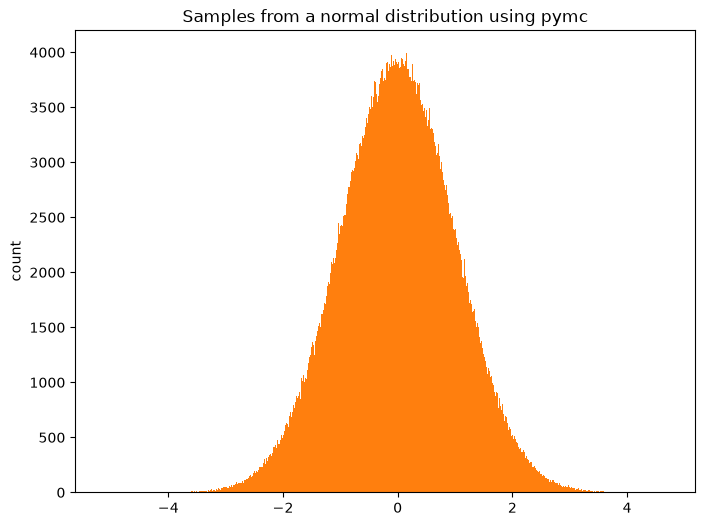

In [39]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(avr, color="C1", bins=1000)
ax.set(title="Samples from a normal distribution using pymc", ylabel="count");

Se empezó con los datos observados en el artículo proporcionado en clase, donde ponemos las 15 muestras y los valores de las muestras, la población y los valores para el sistema de ecuaciones

In [40]:
# Días observados (15 días)
days = np.arange(1, 16)
# Número de infectados activos observados (I_obs) o casos en cama por día

# (Puedes ajustar estos valores con los datos específicos de tu ejercicio)
I_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]) 

N = 763   #población total
I0 = I_obs[0]
S0 = N - I0
R0 = 0
y0 = [S0, I0, R0]


Tomé el modelo SIR que ya habia planteado para la tarea con Metropolis Hastings

In [41]:
def SIR(t, y, a, b):
    S, I, R = y
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return [dSdt, dIdt, dRdt]

En la función de log posterior usamos los parametros theta, t_data, I_data y N, donde 
1. theta: Contiene los parámetros del modelo que queremos estimar (en nuestro modelo SIR, las tasas $a$ y $b$).
2. t_data: El vector con el tiempo en días de las observaciones.
3. I_data: El vector con los datos reales de infectados observados.
4. N: El tamaño de la población total fija.

En el contexto de la **inferencia estadística bayesiana** y los métodos de muestreo, la función log evalúa qué tan bueno es un conjunto propuesto de parámetros ($\theta$) para explicar los datos reales que observamos.

Matemáticamente, esta función calcula el logaritmo de la distribución a posteriori basándose en el Teorema de Bayes:

$$\log(\text{Posterior}) = \log(\text{Likelihood}) + \log(\text{Prior}) + \text{constante}$$

Trabajar en **escala logarítmica (log-space)** es un estándar numérico obligatorio en programación científica para evitar el *underflow* numérico (es decir, que las computadoras reduzcan las probabilidades a cero absoluto al multiplicar muchos números decimales pequeños).

In [42]:
def log_posterior(theta, t_data, I_data, N):
    a, b = theta
    
    # Restricción física: los parámetros no pueden ser negativos
    if a < 0 or b < 0:
        return -np.inf
        
    # Condiciones iniciales de la población del internado (N = 763, I(0) = 1)
    S0 = N - I_data[0]
    I0 = I_data[0]
    R0 = 0.0
    y0 = [S0, I0, R0]
    
    t_span = (t_data[0], t_data[-1])
    try:
        sol = solve_ivp(modelo_sir, t_span, y0, args=(a, b), t_eval=t_data)
        if not sol.success or len(sol.y[1]) != len(I_data):
            return -np.inf
        I_pred = sol.y[1]
    except:
        return -np.inf
        
    # Likelihood con error gaussiano para comparar con los datos de infectados reales
    sigma_error = 10.0  # Desviación estándar estimada para los datos del internado
    sse = np.sum((I_data - I_pred)**2)
    log_lik = -len(I_data) / 2 * np.log(2 * np.pi * sigma_error**2) - sse / (2 * sigma_error**2)
    
    return log_lik

def f(a, b, t_data, I_data, N):
    lp = log_posterior([a, b], t_data, I_data, N)
    return np.exp(lp) if not np.isinf(lp) else 0.0

Utilizando solve_ivp para resolver el sistema de ecuaciones del modelo SIR:

In [43]:
def solve_sir(beta, gamma, t_eval):
    # Resolver usando scipy solve_ivp
    sol = solve_ivp(
        fun=lambda t, y: sir_model(t, y, beta, gamma),
        t_span=(t_eval[0], t_eval[-1]),
        y0=y0,
        t_eval=t_eval,
        method='RK45'
    )
    return sol.y[1] # Retornamos la trayectoria de Infectados I(t)

## Explicación del Operador `sir_ode_op` en PyTensor / PyMC

Este bloque de código conecta una función de Python (que resuelve un sistema de ecuaciones diferenciales con `scipy`) con el grafo computacional de **PyTensor** para que **PyMC** pueda integrarlo dentro de su modelo probabilístico y optimizarlo mediante muestreo bayesiano.

### 1. El Decorador de PyTensor (`@pytensor.compile.ops.as_op`)
```python
@pytensor.compile.ops.as_op(
    itypes=[pt.dscalar, pt.dscalar],  # Parámetros 'a' y 'b' que estimaremos
    otypes=[pt.dvector]               # Regresa el vector de infectados predichos I(t)
)

In [44]:
@pytensor.compile.ops.as_op(
    itypes=[pt.dscalar, pt.dscalar],  # Parámetros 'a' y 'b' que estimaremos
    otypes=[pt.dvector]               # Regresa el vector de infectados predichos I(t)
)
def sir_ode_op(a, b):
    # Condición inicial basada en tus datos
    S0 = N - I_obs[0]
    I0 = I_obs[0]
    R0 = 0.0
    y0 = [S0, I0, R0]
    
    t_span = (days[0], days[-1])
    sol = solve_ivp(SIR, t_span, y0, args=(a, b), t_eval=days)
    
    if not sol.success:
        # Si falla el integrador, devolvemos ceros o un array penalizado
        return np.zeros_like(days, dtype=float)
    
    return sol.y[1]  # Retornamos solo la trayectoria de infectados I(t)

C:\Users\Jorge Magaña\AppData\Local\Temp\ipykernel_15248\741890126.py:1: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @pytensor.compile.ops.as_op(


se usa halfnormal para que los parámetros sean positivos, se devuelve la trayectoria de infectados I(t) para cada par de parámetros (a, b), para la gráfica de la distribución posterior de los parámetros a y b, se puede usar un histograma o un gráfico de densidad.

se resuelve la edo dentro del grafo, y sabemos que los datos siguen uns¿a distribución normal sobre la prediccion de la edo y se usan los samples de PM

In [ ]:
with pm.Model() as sir_pymc_model:
    
    # 1. Priors para los parámetros a (beta) y b (gamma)
  #
    a = pm.HalfNormal("a", sigma=1.0) # Tasa de infección
    b = pm.HalfNormal("b", sigma=1.0) # Tasa de recuperación
    
    # Prior para el error de observación (sigma que pusiste en tu log_posterior)
    sigma = pm.HalfNormal("sigma", sigma=10.0)
    
    # 2. Llamada a la EDO dentro del grafo
    mu_infected = sir_ode_op(a, b)
    
    # 3. Verosimilitud (Likelihood): los datos observados (I_obs) siguen una Normal alrededor de la predicción de la EDO
    y_obs = pm.Normal("y_obs", mu=mu_infected, sigma=sigma, observed=I_obs)
    
    # 4. Muestreo (Sampling)
    # Usamos NUTS (No-U-Turn Sampler)
    idata = pm.sample(draws=1000, tune=1000, chains=2, cores=1) 

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run FromFunctionOp{sir_ode_op}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run FromFunctionOp{sir_ode_op}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run FromFunctionOp{sir_ode_op}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sequential sampling (2 chains in 1 job)
CompoundStep
>CompoundStep
>>Slice: [a]
>>Slice: [b]
>NUTS: [si

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Jorge Magaña\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 797 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Estas graficas muestran la tendencia de $\alpha$ y $\beta$, se imprime el summary para saber que valores promedio nos arrojan los estimadores $\alpha$ y $\beta$

<Figure size 1200x600 with 0 Axes>

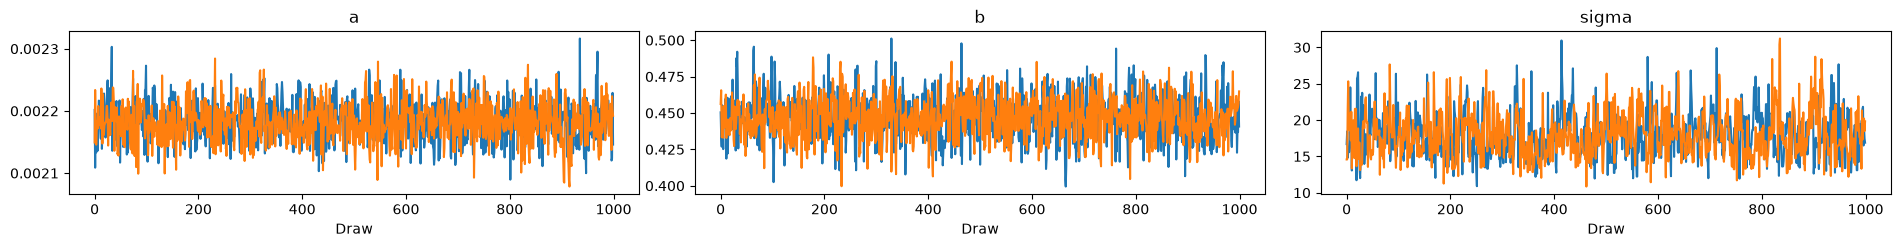

           mean       sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
a      0.002182  3.1e-05   0.0021   0.0022     1624     1474  1.00   7.8e-07  5.9e-07
b        0.4471   0.0148     0.42     0.47     1563     1346  1.00   0.00038  0.00027
sigma      17.9        3       14       23      589      755  1.00      0.13      0.1


In [48]:
#las gráficas quedan como:
plt.figure(figsize=(12, 6))
pm.plot_trace(idata, var_names=["a", "b", "sigma"])
plt.tight_layout()
plt.show()
#Los valores a y b estimados, junto con el sigma de error, se pueden ver en el resumen:
print(pm.summary(idata, var_names=["a", "b", "sigma"]))

Esta gráfica sobrepone los datos con los datos estimados de a y b

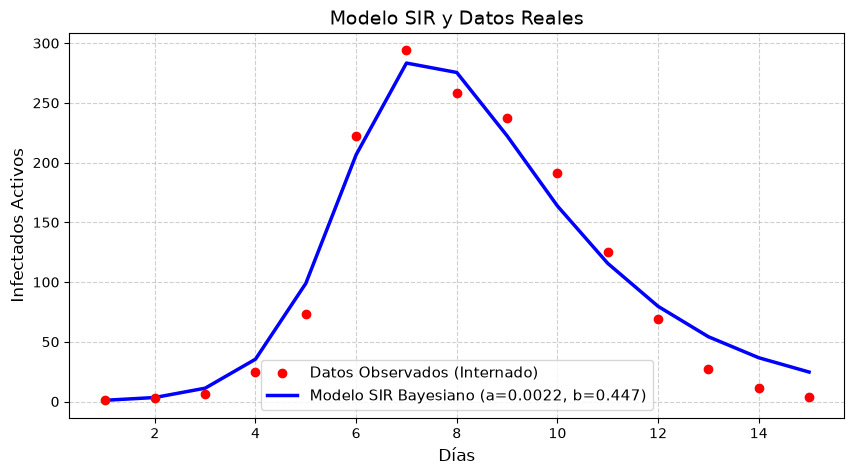

In [53]:
# Extraer las medias posteriores de los parámetros calculados por PyMC
posterior_samples = idata.posterior
a_mean = posterior_samples["a"].mean().values
b_mean = posterior_samples["b"].mean().values

# Resolver la EDO con los parámetros óptimos estimados
sol_opt = solve_ivp(
    SIR, 
    (days[0], days[-1]), 
    [N - I_obs[0], I_obs[0], 0.0], 
    args=(a_mean, b_mean), 
    t_eval=days
)
I_pred_mean = sol_opt.y[1]

# Graficar resultados
plt.figure(figsize=(10, 5))
plt.scatter(days, I_obs, color='red', label='Datos Observados (Internado)', zorder=5)
plt.plot(days, I_pred_mean, color='blue', linewidth=2.5, label=f'Modelo SIR Bayesiano (a={a_mean:.4f}, b={b_mean:.3f})')
plt.xlabel('Días', fontsize=12)
plt.ylabel('Infectados Activos', fontsize=12)
plt.title('Modelo SIR y Datos Reales', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

El desarrollo e implementación del modelo epidemiológico SIR mediante inferencia bayesiana con PyMC permitió estimar de manera robusta y estocástica los parámetros clave del sistema dinámico a partir de los datos observados en el internado. En lugar de asumir valores deterministas fijos, el uso de cadenas de Markov permitió cuantificar la incertidumbre y la distribución de probabilidad asociada a cada tasa del modelo.

   El muestreador NUTS (*No-U-Turn Sampler*) logró explorar eficientemente la distribución a posteriori del espacio de parámetros, alcanzando la estacionariedad con un valor de convergencia $\hat{r} = 1.00$ en todas las cadenas. Esto demuestra que los valores medios obtenidos (como una tasa de transmisión $a \approx 0.0022$ y una tasa de recuperación $b \approx 0.45$) no son producto del azar, sino el resultado de un ajuste estadístico óptimo que equilibra el rigor del sistema de EDOs con la variabilidad de las observaciones reales.

